# 1. Libraries

In [19]:
import numpy as np
import scipy
import scipy.signal as signal
import matplotlib
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from itertools import combinations
from operator import itemgetter
import os

matplotlib.rcParams['font.family']     = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size']       = 12
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['axes.titlesize']  = 12
matplotlib.rcParams['axes.labelsize']  = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12

# 2. Functions

In [20]:
def filter_function_bi(t, t1, t2, rho):
    exp1 = 4; exp2 = 3
    norm = np.max(np.abs(
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ))
    return (
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ) / norm


def resample_and_convolve(signal_data, N, T1_min, T1, filter_data, M, T2_min, T2):
    t_signal = np.linspace(T1_min, T1, N, endpoint=False)
    t_filter = np.linspace(T2_min, T2, M, endpoint=False)
    interp_func = interp1d(t_filter, filter_data, kind='linear', fill_value='extrapolate')
    return t_signal, interp_func(t_signal)


def fit_ridge_closed_form(X, y, alpha):
    n_features = X.shape[1]
    A = X.T @ X + alpha * np.eye(n_features)
    return np.linalg.solve(A, X.T @ y)


def build_lag_matrix(s, lags):
    s    = np.asarray(s)
    lags = np.asarray(lags)
    T    = len(s)
    X    = np.zeros((T, len(lags)))
    for i, lag in enumerate(lags):
        if lag >= 0:
            X[lag:, i] = s[:T - lag]
        else:
            X[:lag, i] = s[-lag:]
    return X


def encoding_model(S, X, lags, reg=1.0, train_frac=0.7):
    """Fit encoding model: X(t) ≈ sum_tau k(tau)*S(t-tau). Returns (r2, corr, kernel, X_pred_test, X_test, valid_range)."""
    S    = np.asarray(S)
    X    = np.asarray(X)
    lags = np.asarray(lags)
    S_lag_full = build_lag_matrix(S, lags)
    T       = len(S)
    t_start = max(0, int(lags.max()))
    t_end   = min(T, T + int(lags.min()))
    S_lag   = S_lag_full[t_start:t_end]
    X_valid = X[t_start:t_end]
    T_train = int(train_frac * len(X_valid))
    S_train, S_test = S_lag[:T_train], S_lag[T_train:]
    X_train, X_test = X_valid[:T_train], X_valid[T_train:]
    S_mean  = S_train.mean(axis=0, keepdims=True)
    X_mean  = X_train.mean()
    w       = fit_ridge_closed_form(S_train - S_mean, X_train - X_mean, alpha=reg)
    X_pred  = (S_test - S_mean) @ w + X_mean
    ss_res  = np.sum((X_test - X_pred)**2)
    ss_tot  = np.sum((X_test - X_test.mean())**2)
    r2      = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    corr    = np.corrcoef(X_test, X_pred)[0, 1]
    return r2, corr, w, X_pred, X_test, (t_start, t_end)

# 3. Parameters

In [21]:
#path_flyfilters = 'user-path-to-Flyfilters'
#path_natvideos  = 'user-path-to-NaturalVideo'
#path_div        = 'user-path-to-Data'
path_flyfilters = os.path.abspath('..') + '/Flyfilters'
path_natvideos  = os.path.abspath('..') + '/NaturalVideo'
path_div        = os.path.abspath('..') + '/Data'

string_movie = [
    'MovieBees_51pix', 'TreeFruit_Wind_51pix', 'MovieChickens_51pix',
    'MovieSquirrel_51pix', 'MovieWaterfall_51pix', 'MovieWolf_51pix',
    'MovieCows_51pix', 'MovieDucks2_51pix',
    '1_bushes', '2_water', '3_leaves', '4_fish', '5_opticflow'
]
T_max_movie_array = np.array([
    7.58333333, 32.333333333333336, 13.8, 26.0,
    10.03448275862069, 27.608695652173914, 20.28, 32.333333,
    10, 20, 20, 20, 20])
N_movies = len(string_movie)

dt         = 0.001
T_max      = 200
t_min_plot = 80
lags       = np.arange(0, 20)

string_npathway = ['Medulla, ON', 'Medulla, OFF', 'Lamina']
color_pathway   = {0: 'yellow', 1: 'darkorange', 2: 'olive'}

pathways = [
    {'name': 'Lamina',
     'n_pathway': 2,
     'file_names': ['L1', 'L2', 'L3'],
     'plot_names': ['L1', 'L2', 'L3']},
    {'name': 'ON Medulla',
     'n_pathway': 0,
     'file_names': ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
     'plot_names': ['Mi1', 'Mi9', 'Tm3', 'Mi4']},
    {'name': 'OFF Medulla',
     'n_pathway': 1,
     'file_names': ['Tm2_OFF', 'Tm1_OFF', 'Tm4_OFF', 'Tm9_OFF'],
     'plot_names': ['Tm2', 'Tm1', 'Tm4', 'Tm9']},
]

# 4. N = 2 neurons

## 4.1 Compute

In [22]:
N_neurons = 2

N_comb_n2 = {}
for pway in pathways:
    N_p = len(pway['file_names'])
    tl  = list(np.repeat(np.arange(N_p) + 1, N_neurons))
    ci  = np.array(list(set(combinations(tl, N_neurons)))) - 1
    N_comb_n2[pway['n_pathway']] = ci.shape[0]

error_array_n2 = np.zeros((3, N_movies, max(N_comb_n2.values())))

for Par_movie in range(N_movies):
    T_mv  = T_max_movie_array[Par_movie]
    raw   = np.loadtxt(path_natvideos + '/TracesNatural' + string_movie[Par_movie] + '.txt')
    raw   = np.reshape(np.transpose(raw), -1)
    T_arr = np.linspace(0, T_mv * 20, raw.size)
    cut   = np.where(T_arr >= T_mv * 20)[0][0]
    raw   = raw[:cut]
    T_arr = T_arr[:cut]
    Nt_tr = raw.size
    t_sig = np.linspace(0, T_arr[-1], Nt_tr, endpoint=False)
    den   = signal.convolve(raw, np.exp(-t_sig / 0.1), mode='full')[:Nt_tr]
    stim  = den[t_min_plot:] - den[t_min_plot:].mean()
    stim /= stim.std()

    for pway in pathways:
        n_pw   = pway['n_pathway']
        N_p    = len(pway['file_names'])
        fnames = pway['file_names']

        Lpars = np.zeros((N_p, 4))
        for ii, fname in enumerate(fnames):
            p = np.loadtxt(path_flyfilters + '/' + fname + '_filter_parameters_polished.txt')
            Lpars[ii] = [1, 1 - p[2], p[0], p[1]]

        tl       = list(np.repeat(np.arange(N_p) + 1, N_neurons))
        comb_idx = np.array(list(set(combinations(tl, N_neurons)))) - 1
        N_comb   = comb_idx.shape[0]
        Error    = np.zeros(N_comb)

        for i_c in range(N_comb):
            conv_sig = np.zeros(Nt_tr)
            for i_n in range(N_neurons):
                Pol, rho, Tb1, Tb2 = Lpars[comb_idx[i_c, i_n]]
                Fenc = Pol * filter_function_bi(t_sig, Tb1, Tb2, rho)
                conv_sig += (
                    signal.convolve(den + np.random.normal(size=Nt_tr, scale=1.0),
                                    Fenc, mode='full')[:Nt_tr]
                    + np.random.normal(size=Nt_tr, scale=2.0))

            net = conv_sig[t_min_plot:] - conv_sig[t_min_plot:].mean()
            net /= net.std()
            Error[i_c], *_ = encoding_model(stim, net, lags=lags, reg=10.0)

        isort = np.loadtxt(path_natvideos + '/idx_SortedSNR_N_' + str(N_neurons) + '_' +
                           string_npathway[n_pw] + '.txt', dtype=int)
        error_array_n2[n_pw, Par_movie, :N_comb] = Error[isort]

print('N=2 done.')

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_96343/3312334748.py:55: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  isort = np.loadtxt(path_natvideos + '/idx_SortedSNR_N_' + str(N_neurons) + '_' +


N=2 done.


## 4.2 Encoder traces (first video, Lamina)

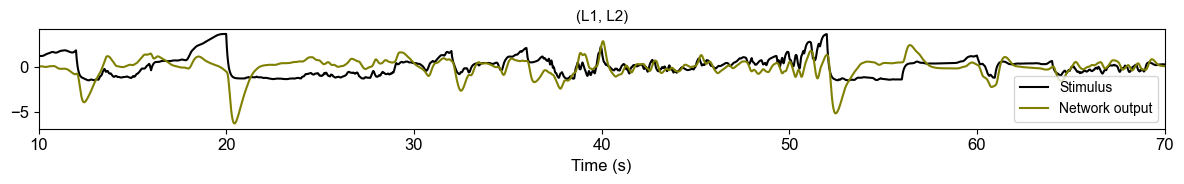

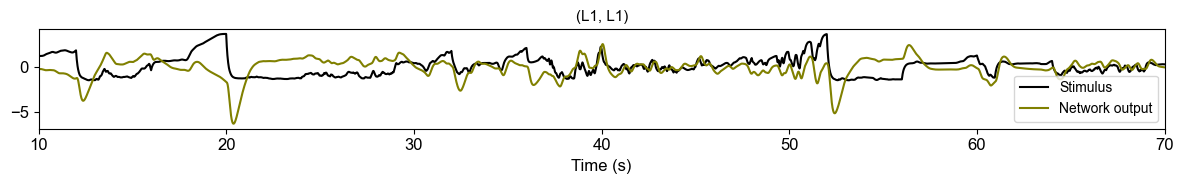

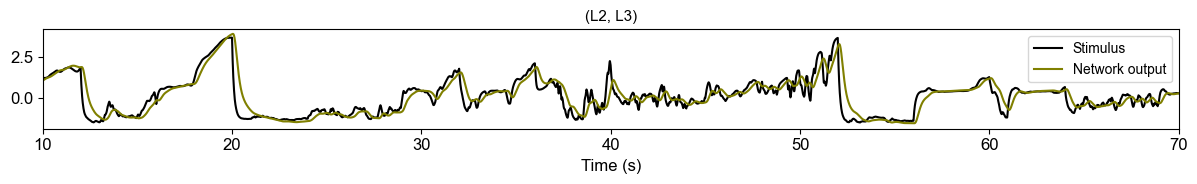

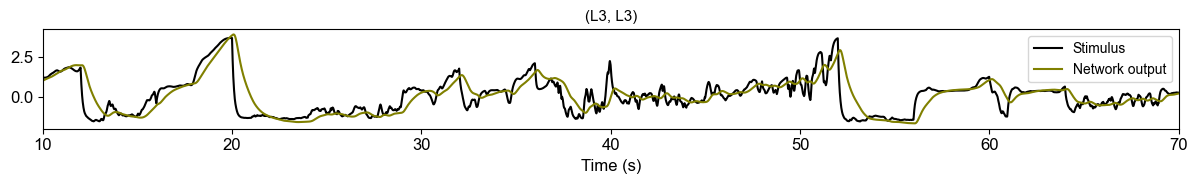

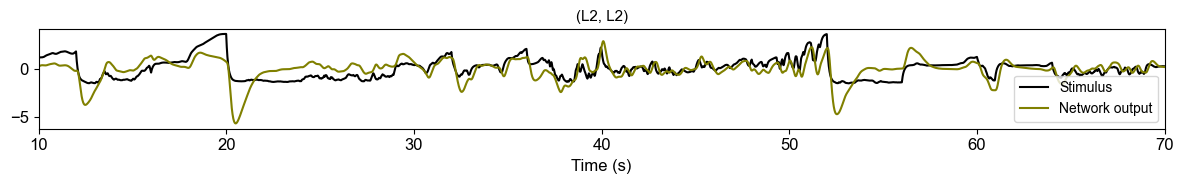

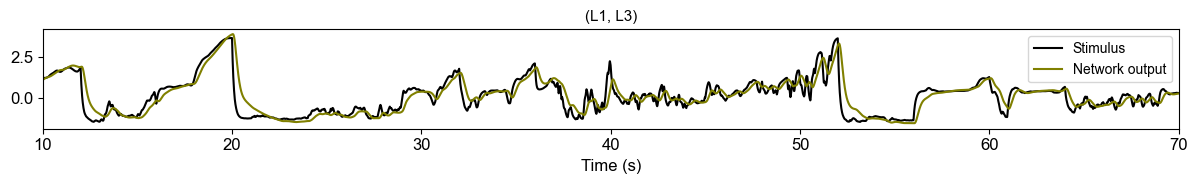

In [23]:
N_neurons      = 2
Par_movie_plot = 8

pway_lam = next(p for p in pathways if p['name'] == 'Lamina')
n_pw     = pway_lam['n_pathway']
N_p      = len(pway_lam['file_names'])
fnames   = pway_lam['file_names']
pnames   = pway_lam['plot_names']
col      = color_pathway[n_pw]

T_mv  = T_max_movie_array[Par_movie_plot]
raw   = np.loadtxt(path_natvideos + '/TracesNatural' + string_movie[Par_movie_plot] + '.txt')
raw   = np.reshape(np.transpose(raw), -1)
T_arr = np.linspace(0, T_mv * 20, raw.size)
cut   = np.where(T_arr >= T_mv * 20)[0][0]
raw   = raw[:cut]
T_arr = T_arr[:cut]
Nt_tr = raw.size
t_sig = np.linspace(0, T_arr[-1], Nt_tr, endpoint=False)
den   = signal.convolve(raw, np.exp(-t_sig / 0.1), mode='full')[:Nt_tr]
stim  = den[t_min_plot:] - den[t_min_plot:].mean()
stim /= stim.std()

Lpars = np.zeros((N_p, 4))
for ii, fname in enumerate(fnames):
    p = np.loadtxt(path_flyfilters + '/' + fname + '_filter_parameters_polished.txt')
    Lpars[ii] = [1, 1 - p[2], p[0], p[1]]

tl       = list(np.repeat(np.arange(N_p) + 1, N_neurons))
comb_idx = np.array(list(set(combinations(tl, N_neurons)))) - 1
N_comb   = comb_idx.shape[0]
string_comb = [tuple(itemgetter(*comb_idx[ii, :])(pnames)) for ii in range(N_comb)]

for i_c in range(N_comb):
    conv_sig = np.zeros(Nt_tr)
    for i_n in range(N_neurons):
        Pol, rho, Tb1, Tb2 = Lpars[comb_idx[i_c, i_n]]
        Fenc = Pol * filter_function_bi(t_sig, Tb1, Tb2, rho)
        conv_sig += (
            signal.convolve(den + np.random.normal(size=Nt_tr, scale=1.0),
                            Fenc, mode='full')[:Nt_tr]
            + np.random.normal(size=Nt_tr, scale=2.0))

    net = conv_sig[t_min_plot:] - conv_sig[t_min_plot:].mean()
    net /= net.std()

    Fig, ax1 = plt.subplots(1, figsize=(12, 2))
    ax1.plot(t_sig[t_min_plot:], stim, color='k',  label='Stimulus')
    ax1.plot(t_sig[t_min_plot:], net,  color=col,  label='Network output')
    ax1.set_xlim(10, 70)
    ax1.set_xlabel('Time (s)', fontsize=12)
    ax1.set_title('(' + ', '.join(string_comb[i_c]) + ')', fontsize=11)
    ax1.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

## 4.3 Correlation vs combinations

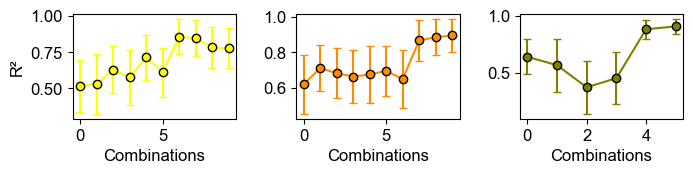

In [25]:
Fig, ax = plt.subplots(1, 3, figsize=(7, 1.9))
plt.subplots_adjust(wspace=0.4)
for n_pw in range(3):
    N_comb = N_comb_n2[n_pw]
    col    = color_pathway[n_pw]
    ax[n_pw].errorbar(
        np.arange(N_comb),
        np.mean(error_array_n2[n_pw, :, :N_comb], axis=0),
        yerr=np.std(error_array_n2[n_pw, :, :N_comb], axis=0),
        color=col, marker='o', capsize=3, markeredgecolor='k')
    ax[n_pw].set_xlabel('Combinations', fontsize=12)
ax[0].set_ylabel('R²', fontsize=12)
plt.tight_layout()
plt.show()

## 4.4 Std vs temporal diversity

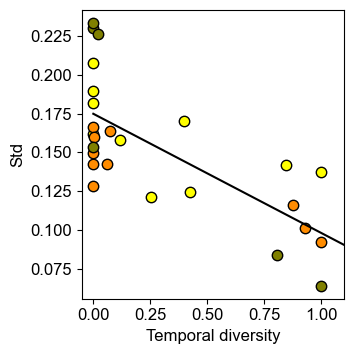

In [26]:
N_neurons = 2

Fig, ax = plt.subplots(1, figsize=(3.7, 3.7))
coef_div_all = np.array([])
std_all      = np.array([])
for n_pw in range(3):
    N_comb   = N_comb_n2[n_pw]
    col      = color_pathway[n_pw]
    coef_div = np.loadtxt(path_div + '/idx_sort_div_and_diversity_coef_' +
                          string_npathway[n_pw] + '_N_neurons_' + str(N_neurons) + '.txt')
    std_vals = np.std(error_array_n2[n_pw, :, :N_comb], axis=0)
    ax.plot(coef_div, std_vals, color=col, marker='o', markeredgecolor='k',
            linestyle='none', markersize=7.5)
    coef_div_all = np.append(coef_div_all, coef_div)
    std_all      = np.append(std_all, std_vals)

result = np.polyfit(coef_div_all, std_all, 1)
x_fit  = np.linspace(0, 1.1, 50)
ax.plot(x_fit, np.polyval(result, x_fit), color='k')
ax.set_xlabel('Temporal diversity', fontsize=12)
ax.set_ylabel('Std', fontsize=12)
ax.set_xlim(-0.05, 1.1)
ax.tick_params(labelsize=12)
plt.tight_layout()
#plt.savefig('Std_TempDiversity_N2.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 5. N = 3 neurons

## 5.1 Compute

In [27]:
N_neurons = 3

N_comb_n3 = {}
for pway in pathways:
    N_p = len(pway['file_names'])
    tl  = list(np.repeat(np.arange(N_p) + 1, N_neurons))
    ci  = np.array(list(set(combinations(tl, N_neurons)))) - 1
    N_comb_n3[pway['n_pathway']] = ci.shape[0]

error_array_n3 = np.zeros((3, N_movies, max(N_comb_n3.values())))

for Par_movie in range(N_movies):
    T_mv  = T_max_movie_array[Par_movie]
    raw   = np.loadtxt(path_natvideos + '/TracesNatural' + string_movie[Par_movie] + '.txt')
    raw   = np.reshape(np.transpose(raw), -1)
    T_arr = np.linspace(0, T_mv * 20, raw.size)
    cut   = np.where(T_arr >= T_mv * 20)[0][0]
    raw   = raw[:cut]
    T_arr = T_arr[:cut]
    Nt_tr = raw.size
    t_sig = np.linspace(0, T_arr[-1], Nt_tr, endpoint=False)
    den   = signal.convolve(raw, np.exp(-t_sig / 0.1), mode='full')[:Nt_tr]
    stim  = den[t_min_plot:] - den[t_min_plot:].mean()
    stim /= stim.std()

    for pway in pathways:
        n_pw   = pway['n_pathway']
        N_p    = len(pway['file_names'])
        fnames = pway['file_names']

        Lpars = np.zeros((N_p, 4))
        for ii, fname in enumerate(fnames):
            p = np.loadtxt(path_flyfilters + '/' + fname + '_filter_parameters_polished.txt')
            Lpars[ii] = [1, 1 - p[2], p[0], p[1]]

        tl       = list(np.repeat(np.arange(N_p) + 1, N_neurons))
        comb_idx = np.array(list(set(combinations(tl, N_neurons)))) - 1
        N_comb   = comb_idx.shape[0]
        Error    = np.zeros(N_comb)

        for i_c in range(N_comb):
            conv_sig = np.zeros(Nt_tr)
            for i_n in range(N_neurons):
                Pol, rho, Tb1, Tb2 = Lpars[comb_idx[i_c, i_n]]
                Fenc = Pol * filter_function_bi(t_sig, Tb1, Tb2, rho)
                conv_sig += (
                    signal.convolve(den + np.random.normal(size=Nt_tr, scale=1.0),
                                    Fenc, mode='full')[:Nt_tr]
                    + np.random.normal(size=Nt_tr, scale=2.0))

            net = conv_sig[t_min_plot:] - conv_sig[t_min_plot:].mean()
            net /= net.std()
            Error[i_c], *_ = encoding_model(stim, net, lags=lags, reg=10.0)

        isort = np.loadtxt(path_natvideos + '/idx_SortedSNR_N_' + str(N_neurons) + '_' +
                           string_npathway[n_pw] + '.txt', dtype=int)
        error_array_n3[n_pw, Par_movie, :N_comb] = Error[isort]

print('N=3 done.')

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_96343/3745284474.py:55: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  isort = np.loadtxt(path_natvideos + '/idx_SortedSNR_N_' + str(N_neurons) + '_' +


N=3 done.


## 5.2 Encoder traces (first video, Lamina)

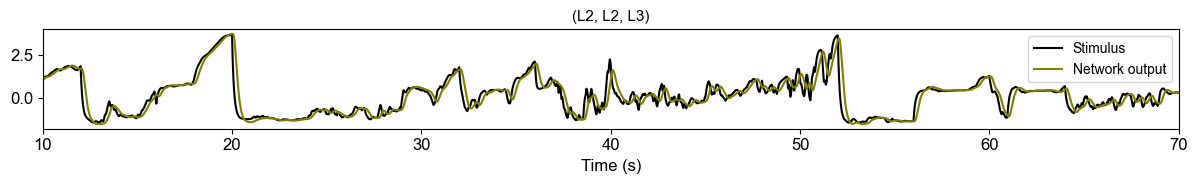

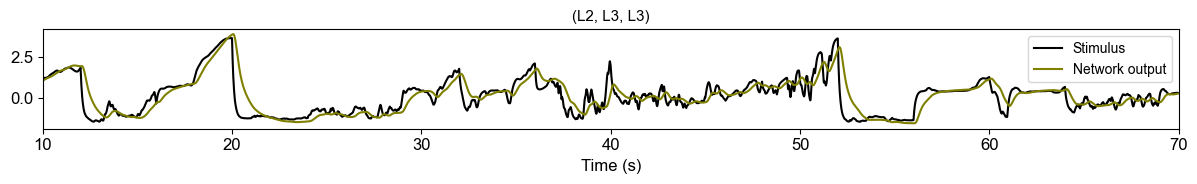

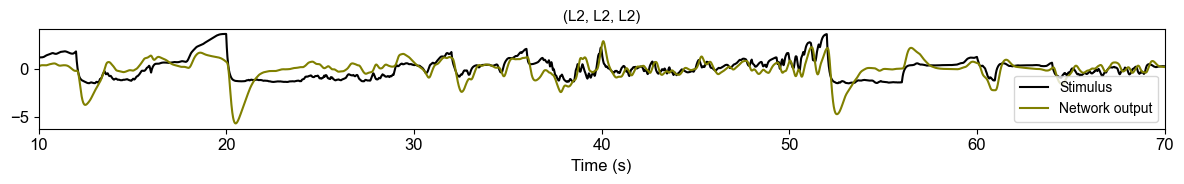

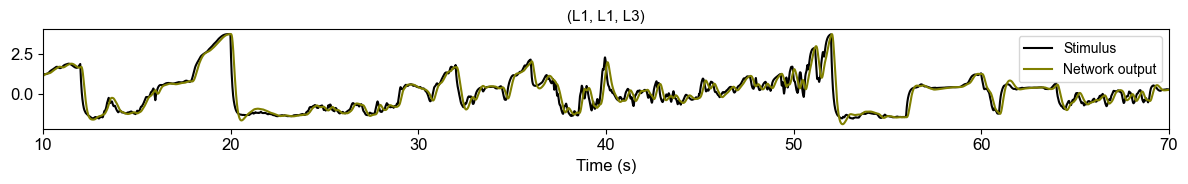

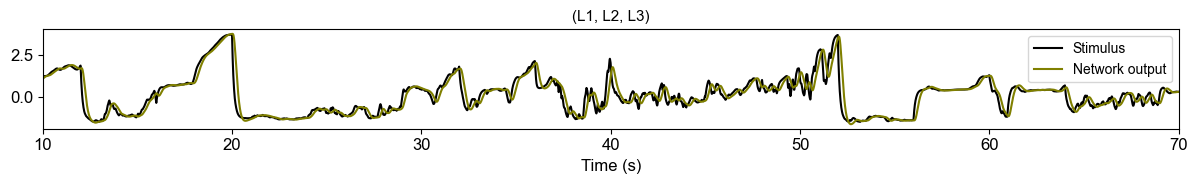

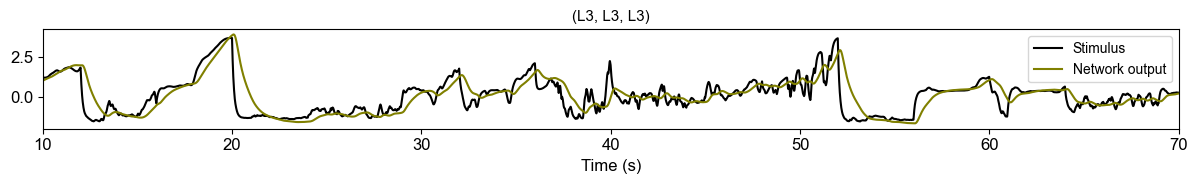

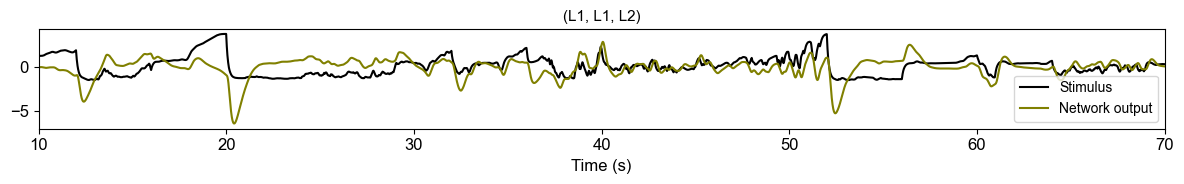

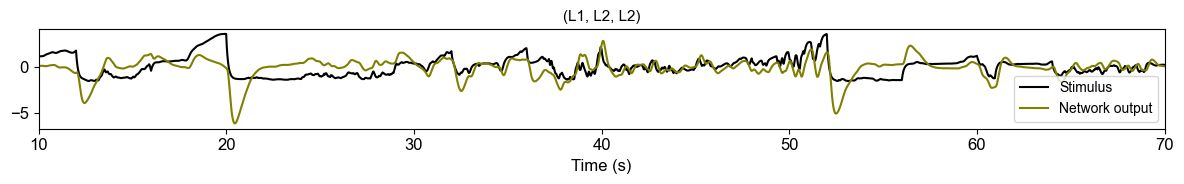

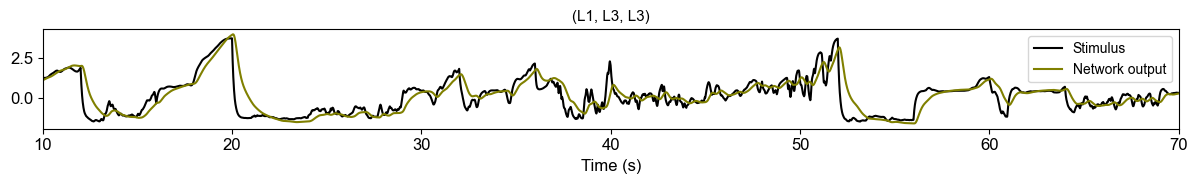

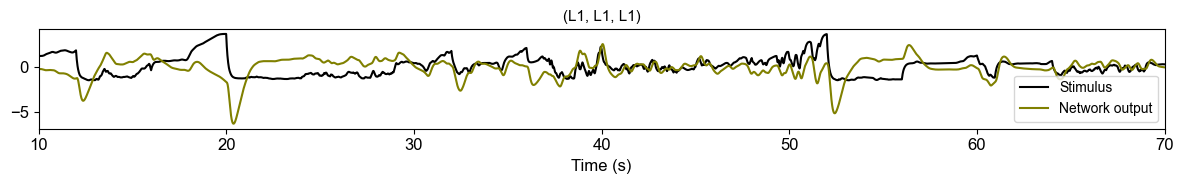

In [35]:
N_neurons      = 3
Par_movie_plot = 8

pway_lam = next(p for p in pathways if p['name'] == 'Lamina')
n_pw     = pway_lam['n_pathway']
N_p      = len(pway_lam['file_names'])
fnames   = pway_lam['file_names']
pnames   = pway_lam['plot_names']
col      = color_pathway[n_pw]

T_mv  = T_max_movie_array[Par_movie_plot]
raw   = np.loadtxt(path_natvideos + '/TracesNatural' + string_movie[Par_movie_plot] + '.txt')
raw   = np.reshape(np.transpose(raw), -1)
T_arr = np.linspace(0, T_mv * 20, raw.size)
cut   = np.where(T_arr >= T_mv * 20)[0][0]
raw   = raw[:cut]
T_arr = T_arr[:cut]
Nt_tr = raw.size
t_sig = np.linspace(0, T_arr[-1], Nt_tr, endpoint=False)
den   = signal.convolve(raw, np.exp(-t_sig / 0.1), mode='full')[:Nt_tr]
stim  = den[t_min_plot:] - den[t_min_plot:].mean()
stim /= stim.std()

Lpars = np.zeros((N_p, 4))
for ii, fname in enumerate(fnames):
    p = np.loadtxt(path_flyfilters + '/' + fname + '_filter_parameters_polished.txt')
    Lpars[ii] = [1, 1 - p[2], p[0], p[1]]

tl       = list(np.repeat(np.arange(N_p) + 1, N_neurons))
comb_idx = np.array(list(set(combinations(tl, N_neurons)))) - 1
N_comb   = comb_idx.shape[0]
string_comb = [tuple(itemgetter(*comb_idx[ii, :])(pnames)) for ii in range(N_comb)]

for i_c in range(N_comb):
    conv_sig = np.zeros(Nt_tr)
    for i_n in range(N_neurons):
        Pol, rho, Tb1, Tb2 = Lpars[comb_idx[i_c, i_n]]
        Fenc = Pol * filter_function_bi(t_sig, Tb1, Tb2, rho)
        conv_sig += (
            signal.convolve(den + np.random.normal(size=Nt_tr, scale=1.0),
                            Fenc, mode='full')[:Nt_tr]
            + np.random.normal(size=Nt_tr, scale=2.0))

    net = conv_sig[t_min_plot:] - conv_sig[t_min_plot:].mean()
    net /= net.std()

    Fig, ax1 = plt.subplots(1, figsize=(12, 2))
    ax1.plot(t_sig[t_min_plot:], stim, color='k',  label='Stimulus')
    ax1.plot(t_sig[t_min_plot:], net,  color=col,  label='Network output')
    ax1.set_xlim(10, 70)
    ax1.set_xlabel('Time (s)', fontsize=12)
    ax1.set_title('(' + ', '.join(string_comb[i_c]) + ')', fontsize=11)
    ax1.legend(fontsize=10)
    plt.tight_layout()
    if np.logical_or(i_c == 4, i_c == 6):
        plt.savefig("Traces_NatMovies_triples_"+str(i_c)+".pdf", bbox_inches = 'tight', dpi = 300)
    plt.show()

## 5.3 Correlation vs combinations

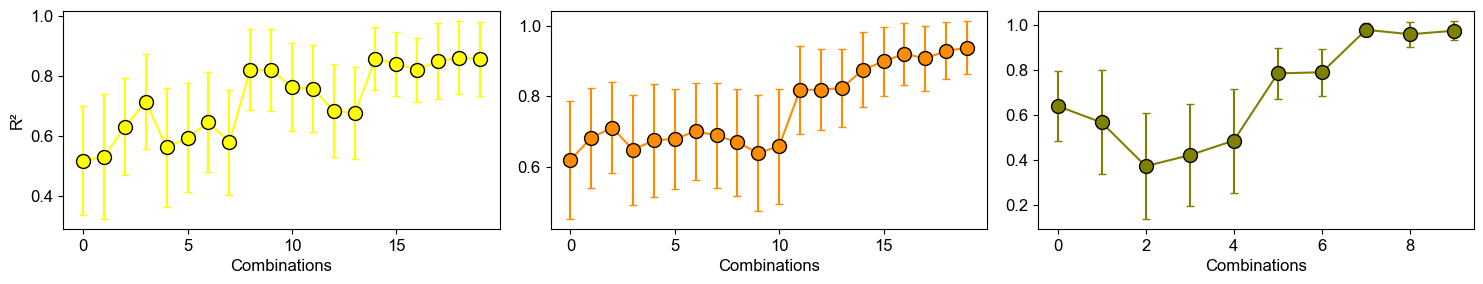

In [40]:
Fig, ax = plt.subplots(1, 3, figsize=(15, 3))
plt.subplots_adjust(wspace=0.4)
for n_pw in range(3):
    N_comb = N_comb_n3[n_pw]
    col    = color_pathway[n_pw]
    ax[n_pw].errorbar(
        np.arange(N_comb),
        np.mean(error_array_n3[n_pw, :, :N_comb], axis=0),
        yerr=np.std(error_array_n3[n_pw, :, :N_comb], axis=0),
        color=col, marker='o', capsize=3, markeredgecolor='k', markersize = 10)
    ax[n_pw].set_xlabel('Combinations', fontsize=12)
ax[0].set_ylabel('R²', fontsize=12)
plt.tight_layout()
plt.savefig("R2_NaturalMovies_triplets.pdf", bbox_inches = 'tight', dpi = 300)
plt.show()

## 5.4 Std vs temporal diversity

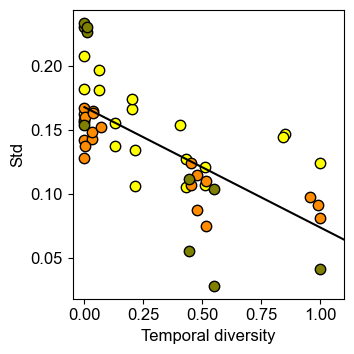

In [37]:
N_neurons = 3

Fig, ax = plt.subplots(1, figsize=(3.7, 3.7))
coef_div_all = np.array([])
std_all      = np.array([])
for n_pw in range(3):
    N_comb   = N_comb_n3[n_pw]
    col      = color_pathway[n_pw]
    coef_div = np.loadtxt(path_div + '/idx_sort_div_and_diversity_coef_' +
                          string_npathway[n_pw] + '_N_neurons_' + str(N_neurons) + '.txt')
    std_vals = np.std(error_array_n3[n_pw, :, :N_comb], axis=0)
    ax.plot(coef_div, std_vals, color=col, marker='o', markeredgecolor='k',
            linestyle='none', markersize=7.5)
    coef_div_all = np.append(coef_div_all, coef_div)
    std_all      = np.append(std_all, std_vals)

result = np.polyfit(coef_div_all, std_all, 1)
x_fit  = np.linspace(0, 1.1, 50)
ax.plot(x_fit, np.polyval(result, x_fit), color='k')
ax.set_xlabel('Temporal diversity', fontsize=12)
ax.set_ylabel('Std', fontsize=12)
ax.set_xlim(-0.05, 1.1)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig('Std_TempDiversity_triplets.pdf', dpi=300, bbox_inches='tight')
plt.show()